<a href="https://colab.research.google.com/github/aurora-nat/machine-vision-course/blob/main/labs/lab5/instance_segmentation_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instance Segmentation with PyTorch

This notebook is about **instance segmentation** with a dataset using **PyTorch** and **Mask R-CNN**.

We will use the **Penn-Fudan pedestrian dataset**, a standard small dataset for object detection and instance segmentation. The official TorchVision tutorial uses this same dataset to demonstrate fine-tuning a pretrained Mask R-CNN model.

## Learning goals
By the end of this notebook, you should be able to:

- explain the difference between **semantic segmentation** and **instance segmentation**
- understand the dataset format expected by TorchVision detection models
- fine-tune a pretrained **Mask R-CNN**
- train on a custom dataset
- visualize predicted boxes, labels, scores, and masks

Penn-Fudan
- it is small and quick to train on
- each image contains **pedestrian instances**
- each object has a separate mask
- it matches the official TorchVision fine-tuning tutorial

## What is instance segmentation?

- **Semantic segmentation** assigns a class label to every pixel.
- **Instance segmentation** assigns both:
  - a class label to pixels, and
  - a separate object identity for each instance.

Example:
- semantic segmentation can say: “these pixels are person”
- instance segmentation can say: “this is person 1, this is person 2, this is person 3”

In [1]:
# Check PyTorch / TorchVision versions
import torch, torchvision
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA available: True


In [2]:
# Standard imports
import os
import time
import math
import random
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

## Download the Penn-Fudan dataset

The TorchVision fine-tuning tutorial uses the **Penn-Fudan Database for Pedestrian Detection and Segmentation**. It contains **170 images with 345 pedestrian instances**.

In [3]:
# Download dataset if needed
DATA_URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
DATA_ROOT = Path("/content")
ZIP_PATH = DATA_ROOT / "PennFudanPed.zip"
EXTRACTED_DIR = DATA_ROOT / "PennFudanPed"

if not EXTRACTED_DIR.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_ROOT)
    print("Done.")
else:
    print("Dataset already available.")

print("Dataset path:", EXTRACTED_DIR)
print("Number of images:", len(list((EXTRACTED_DIR / "PNGImages").glob("*.png"))))
print("Number of masks :", len(list((EXTRACTED_DIR / "PedMasks").glob("*.png"))))

Extracting dataset...
Done.
Dataset path: /content/PennFudanPed
Number of images: 170
Number of masks : 170


## How the annotations work

Each image has a corresponding mask image.  
In the Penn-Fudan masks, different object instances are stored with different pixel values.  
So one mask image can contain multiple pedestrian instances.

We will convert each unique non-zero value into:
- one binary instance mask
- one bounding box
- one class label (`person = 1`)

In [4]:

class PennFudanDataset(Dataset):
    def __init__(self, root, transforms=None):
        self.root = Path(root)
        self.transforms = transforms
        self.imgs = sorted((self.root / "PNGImages").glob("*.png"))
        self.masks = sorted((self.root / "PedMasks").glob("*.png"))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img_path = self.imgs[idx]
        mask_path = self.masks[idx]

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        mask = np.array(mask)
        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0]  # background is 0

        masks = mask == obj_ids[:, None, None]  # [N, H, W]

        boxes = []
        valid_masks = []

        for i in range(len(obj_ids)):
            pos = np.where(masks[i])
            if pos[0].size == 0 or pos[1].size == 0:
                continue

            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])

            if xmax > xmin and ymax > ymin:
                boxes.append([xmin, ymin, xmax, ymax])
                valid_masks.append(masks[i])

        if len(valid_masks) == 0:
            masks = torch.zeros((0, mask.shape[0], mask.shape[1]), dtype=torch.uint8)
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            area = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            masks = torch.as_tensor(np.array(valid_masks, dtype=np.uint8), dtype=torch.uint8)
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.ones((len(valid_masks),), dtype=torch.int64)  # person class = 1
            area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
            iscrowd = torch.zeros((len(valid_masks),), dtype=torch.int64)

        image_id = torch.tensor([idx])

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd,
        }

        img = F.to_tensor(img)

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

In [5]:

class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, image, target):
        for t in self.transforms:
            image, target = t(image, target)
        return image, target


class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, image, target):
        if random.random() < self.p:
            _, h, w = image.shape
            image = torch.flip(image, dims=[2])

            boxes = target["boxes"].clone()
            if boxes.numel() > 0:
                xmin = w - boxes[:, 2]
                xmax = w - boxes[:, 0]
                boxes[:, 0] = xmin
                boxes[:, 2] = xmax
                target["boxes"] = boxes

            if target["masks"].numel() > 0:
                target["masks"] = torch.flip(target["masks"], dims=[2])

        return image, target


def get_transform(train=True):
    transforms = []
    if train:
        transforms.append(RandomHorizontalFlip(0.5))
    return Compose(transforms)

## Inspect one training sample

In [6]:

dataset_preview = PennFudanDataset(EXTRACTED_DIR, transforms=None)
img, target = dataset_preview[0]

print("Image tensor shape:", img.shape)
print("Boxes shape:", target["boxes"].shape)
print("Masks shape:", target["masks"].shape)
print("Labels:", target["labels"])

Image tensor shape: torch.Size([3, 536, 559])
Boxes shape: torch.Size([2, 4])
Masks shape: torch.Size([2, 536, 559])
Labels: tensor([1, 1])


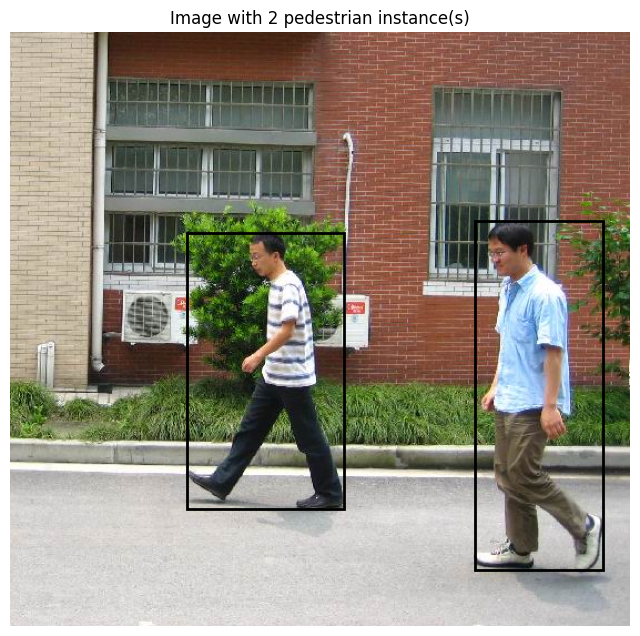

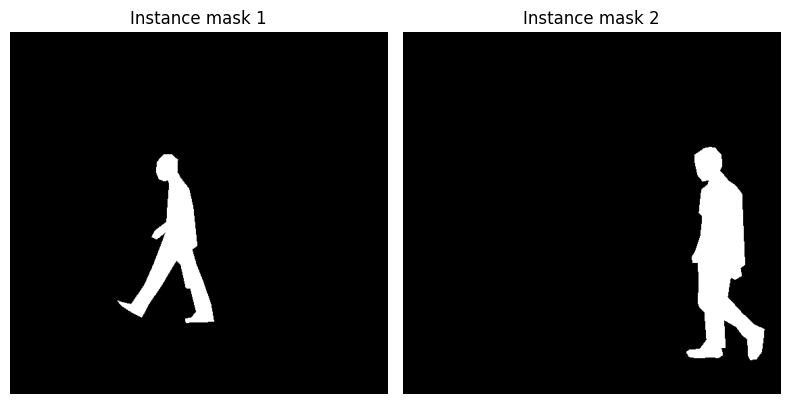

In [7]:

def show_sample(image, target):
    image_np = image.permute(1, 2, 0).numpy()
    masks = target["masks"].numpy()
    boxes = target["boxes"].numpy()

    plt.figure(figsize=(8, 8))
    plt.imshow(image_np)
    ax = plt.gca()

    for box in boxes:
        x1, y1, x2, y2 = box
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2)
        ax.add_patch(rect)

    plt.title(f"Image with {len(boxes)} pedestrian instance(s)")
    plt.axis("off")
    plt.show()

    if len(masks) > 0:
        cols = min(4, len(masks))
        rows = math.ceil(len(masks) / cols)
        plt.figure(figsize=(4 * cols, 4 * rows))
        for i, m in enumerate(masks):
            plt.subplot(rows, cols, i + 1)
            plt.imshow(m, cmap="gray")
            plt.title(f"Instance mask {i+1}")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

show_sample(img, target)

## Train/validation split

Because the dataset is small, we will use a simple random split:
- **80% training**
- **20% validation**

In [8]:
full_dataset = PennFudanDataset(EXTRACTED_DIR, transforms=None)

num_samples = len(full_dataset)
num_train = int(0.8 * num_samples)

indices = torch.randperm(num_samples).tolist()
train_indices = indices[:num_train]
val_indices = indices[num_train:]

train_dataset = torch.utils.data.Subset(
    PennFudanDataset(EXTRACTED_DIR, transforms=get_transform(train=True)),
    train_indices
)
val_dataset = torch.utils.data.Subset(
    PennFudanDataset(EXTRACTED_DIR, transforms=get_transform(train=False)),
    val_indices
)

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, collate_fn=collate_fn, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn, num_workers=0)

print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))

Train samples: 136
Val samples: 34


## Build a Mask R-CNN model

We fine-tune a pretrained **Mask R-CNN** model from TorchVision.

For this dataset there is only one object class:
- class `1` = person

Class `0` is always background in TorchVision detection models.

In [9]:

import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

def get_model_instance_segmentation(num_classes):
    try:
        weights = torchvision.models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
        model = maskrcnn_resnet50_fpn(weights=weights)
    except Exception:
        model = maskrcnn_resnet50_fpn(pretrained=True)

    in_features_box = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features_box, num_classes)

    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, hidden_layer, num_classes)

    return model

num_classes = 2  # background + person
model = get_model_instance_segmentation(num_classes)
print(type(model).__name__)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:03<00:00, 49.4MB/s]


MaskRCNN


In [10]:

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)
print("Using device:", device)

Using device: cuda


## Optimizer and training settings

To make this notebook classroom-friendly, we use:
- SGD optimizer
- a small batch size
- a small number of epochs

In [11]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

num_epochs = 5  # increase to 5 or 10 for better results

## Training loop

TorchVision detection models return a dictionary of loss terms during training:
- classifier loss
- box regression loss
- mask loss
- objectness loss
- RPN box regression loss

We sum them to get the total loss.

In [12]:

def train_one_epoch(model, optimizer, data_loader, device, epoch):
    model.train()
    running_loss = 0.0

    for batch_idx, (images, targets) in enumerate(data_loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        running_loss += losses.item()

        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(data_loader):
            print(
                f"Epoch [{epoch+1}] Batch [{batch_idx+1}/{len(data_loader)}] "
                f"Loss: {losses.item():.4f}"
            )

    return running_loss / max(len(data_loader), 1)

## Simple validation metric

For teaching purposes, we compute a simple **mask IoU** between predictions and ground-truth masks.

This is not the full COCO evaluation protocol, but it is easy to understand:
1. pick high-confidence predicted instances
2. merge them into one foreground mask
3. merge the ground-truth masks into one foreground mask
4. compute foreground IoU

In [13]:

@torch.no_grad()
def evaluate_simple_mask_iou(model, data_loader, device, score_threshold=0.5):
    model.eval()
    ious = []

    for images, targets in data_loader:
        images = [img.to(device) for img in images]
        outputs = model(images)

        for output, target in zip(outputs, targets):
            pred_scores = output["scores"].detach().cpu()
            pred_masks = output["masks"].detach().cpu()

            keep = pred_scores >= score_threshold
            pred_masks = pred_masks[keep]

            if pred_masks.numel() == 0:
                pred_union_mask = torch.zeros(target["masks"].shape[-2:], dtype=torch.bool)
            else:
                pred_union_mask = (pred_masks.squeeze(1) >= 0.5).any(dim=0)

            gt_masks = target["masks"].detach().cpu()
            if gt_masks.numel() == 0:
                gt_union_mask = torch.zeros(pred_union_mask.shape, dtype=torch.bool)
            else:
                gt_union_mask = gt_masks.bool().any(dim=0)

            intersection = (pred_union_mask & gt_union_mask).sum().item()
            union = (pred_union_mask | gt_union_mask).sum().item()

            iou = intersection / union if union > 0 else 1.0
            ious.append(iou)

    return float(np.mean(ious)) if ious else 0.0

In [14]:

train_losses = []
val_ious = []

for epoch in range(num_epochs):
    start = time.time()
    avg_loss = train_one_epoch(model, optimizer, train_loader, device, epoch)
    lr_scheduler.step()

    val_iou = evaluate_simple_mask_iou(model, val_loader, device, score_threshold=0.5)

    train_losses.append(avg_loss)
    val_ious.append(val_iou)

    elapsed = time.time() - start
    print(f"Epoch {epoch+1} finished in {elapsed:.1f}s | avg train loss = {avg_loss:.4f} | val mask IoU = {val_iou:.4f}")

Epoch [1] Batch [10/68] Loss: 0.9783
Epoch [1] Batch [20/68] Loss: 0.5261
Epoch [1] Batch [30/68] Loss: 0.2209
Epoch [1] Batch [40/68] Loss: 0.5812
Epoch [1] Batch [50/68] Loss: 0.2603
Epoch [1] Batch [60/68] Loss: 0.3036
Epoch [1] Batch [68/68] Loss: 0.3109
Epoch 1 finished in 57.5s | avg train loss = 0.5132 | val mask IoU = 0.8178
Epoch [2] Batch [10/68] Loss: 0.3411
Epoch [2] Batch [20/68] Loss: 0.1807
Epoch [2] Batch [30/68] Loss: 0.2857
Epoch [2] Batch [40/68] Loss: 0.3104
Epoch [2] Batch [50/68] Loss: 0.2688
Epoch [2] Batch [60/68] Loss: 0.2581
Epoch [2] Batch [68/68] Loss: 0.2442
Epoch 2 finished in 55.5s | avg train loss = 0.2586 | val mask IoU = 0.8362
Epoch [3] Batch [10/68] Loss: 0.2067
Epoch [3] Batch [20/68] Loss: 0.2874
Epoch [3] Batch [30/68] Loss: 0.1757
Epoch [3] Batch [40/68] Loss: 0.4238
Epoch [3] Batch [50/68] Loss: 0.3392
Epoch [3] Batch [60/68] Loss: 0.1656
Epoch [3] Batch [68/68] Loss: 0.2328
Epoch 3 finished in 55.9s | avg train loss = 0.2225 | val mask IoU = 0.

## Plot training progress

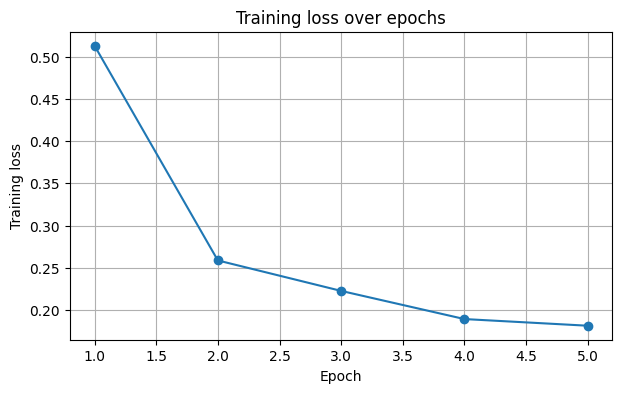

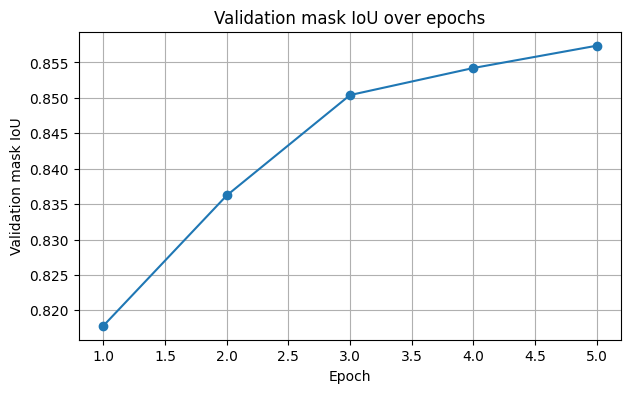

In [15]:

plt.figure(figsize=(7, 4))
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss over epochs")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(range(1, num_epochs + 1), val_ious, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation mask IoU")
plt.title("Validation mask IoU over epochs")
plt.grid(True)
plt.show()

## Run inference and visualize predictions

We will show:
- the original image
- predicted boxes
- predicted instance masks
- confidence scores

Only predictions above a confidence threshold are displayed.

In [16]:

@torch.no_grad()
def predict_one(model, dataset, idx, device, score_threshold=0.5):
    model.eval()
    image, target = dataset[idx]
    output = model([image.to(device)])[0]

    output = {k: v.detach().cpu() for k, v in output.items()}

    keep = output["scores"] >= score_threshold
    output["boxes"] = output["boxes"][keep]
    output["labels"] = output["labels"][keep]
    output["scores"] = output["scores"][keep]
    output["masks"] = output["masks"][keep]

    return image, target, output

In [17]:

def draw_predictions(image, target, output):
    image_np = image.permute(1, 2, 0).numpy()

    plt.figure(figsize=(8, 8))
    plt.imshow(image_np)
    ax = plt.gca()

    gt_boxes = target["boxes"].numpy()
    for box in gt_boxes:
        x1, y1, x2, y2 = box
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, edgecolor="lime")
        ax.add_patch(rect)

    pred_boxes = output["boxes"].numpy()
    pred_scores = output["scores"].numpy()

    for box, score in zip(pred_boxes, pred_scores):
        x1, y1, x2, y2 = box
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, linestyle="--", edgecolor="red")
        ax.add_patch(rect)
        ax.text(x1, y1, f"{score:.2f}", fontsize=10, color="white", bbox=dict(facecolor="red", alpha=0.6))

    plt.title("Green = ground truth, red dashed = prediction")
    plt.axis("off")
    plt.show()

    pred_masks = output["masks"].squeeze(1).numpy() if len(output["masks"]) > 0 else np.array([])
    gt_masks = target["masks"].numpy()

    if len(gt_masks) > 0:
        cols = min(4, len(gt_masks))
        rows = math.ceil(len(gt_masks) / cols)
        plt.figure(figsize=(4 * cols, 4 * rows))
        for i, m in enumerate(gt_masks):
            plt.subplot(rows, cols, i + 1)
            plt.imshow(m, cmap="gray")
            plt.title(f"GT mask {i+1}")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

    if len(pred_masks) > 0:
        cols = min(4, len(pred_masks))
        rows = math.ceil(len(pred_masks) / cols)
        plt.figure(figsize=(4 * cols, 4 * rows))
        for i, m in enumerate(pred_masks):
            plt.subplot(rows, cols, i + 1)
            plt.imshow(m >= 0.5, cmap="gray")
            plt.title(f"Pred mask {i+1}\nscore={pred_scores[i]:.2f}")
            plt.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print("No predictions above threshold.")

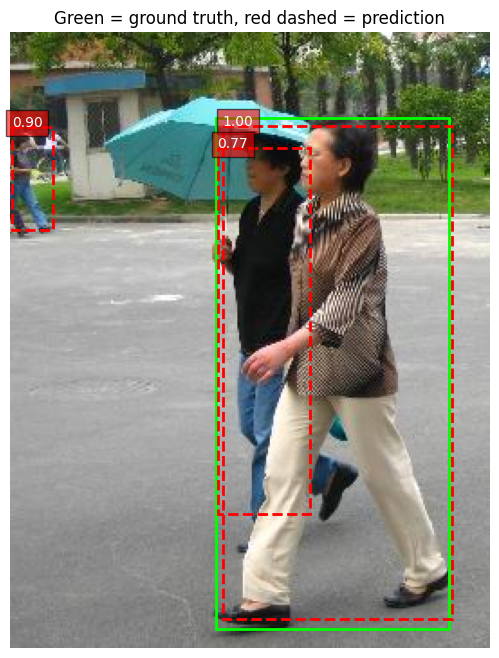

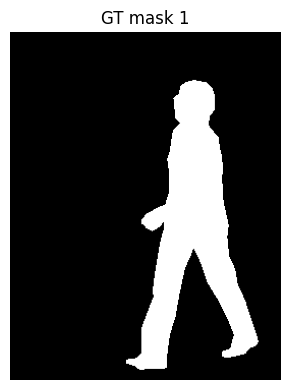

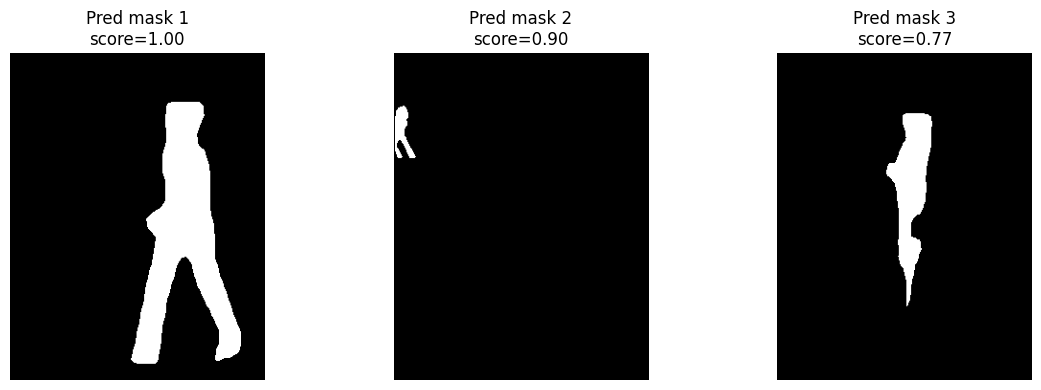

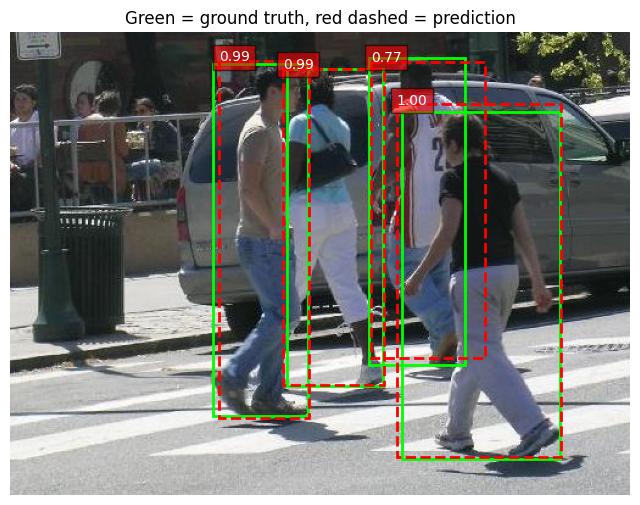

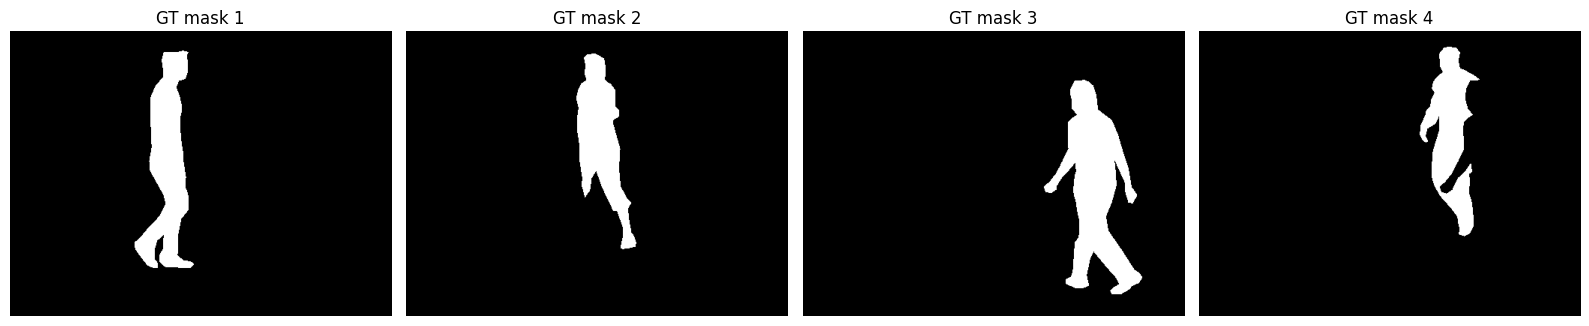

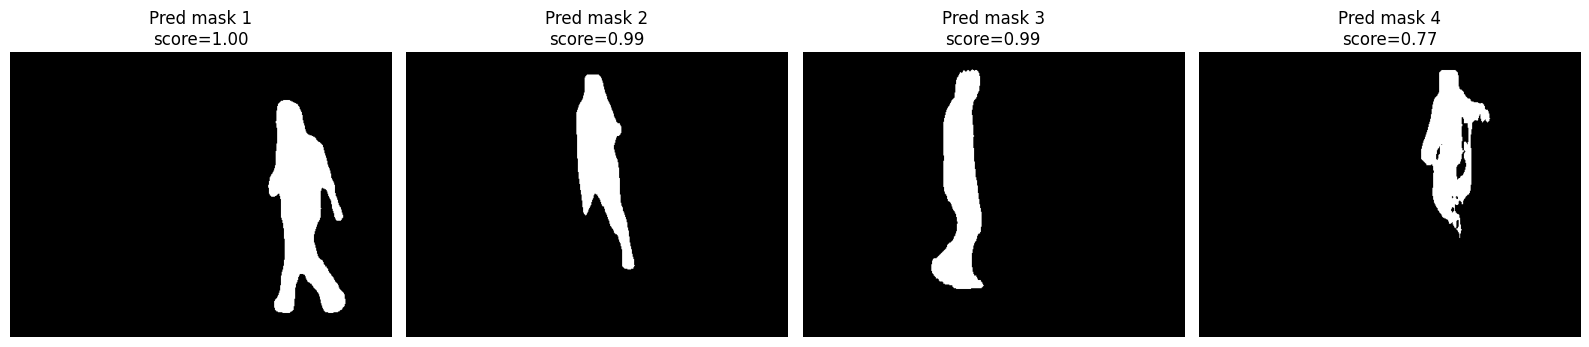

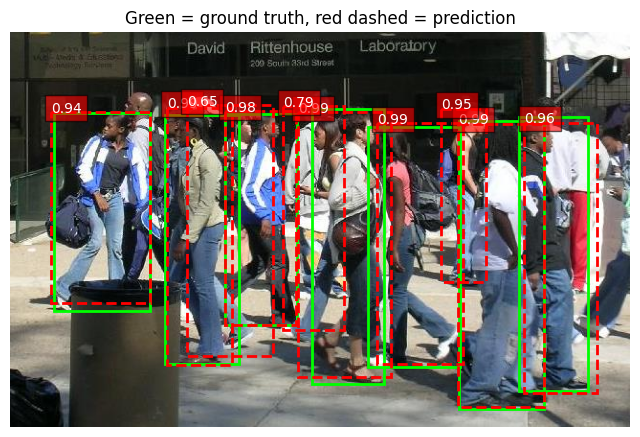

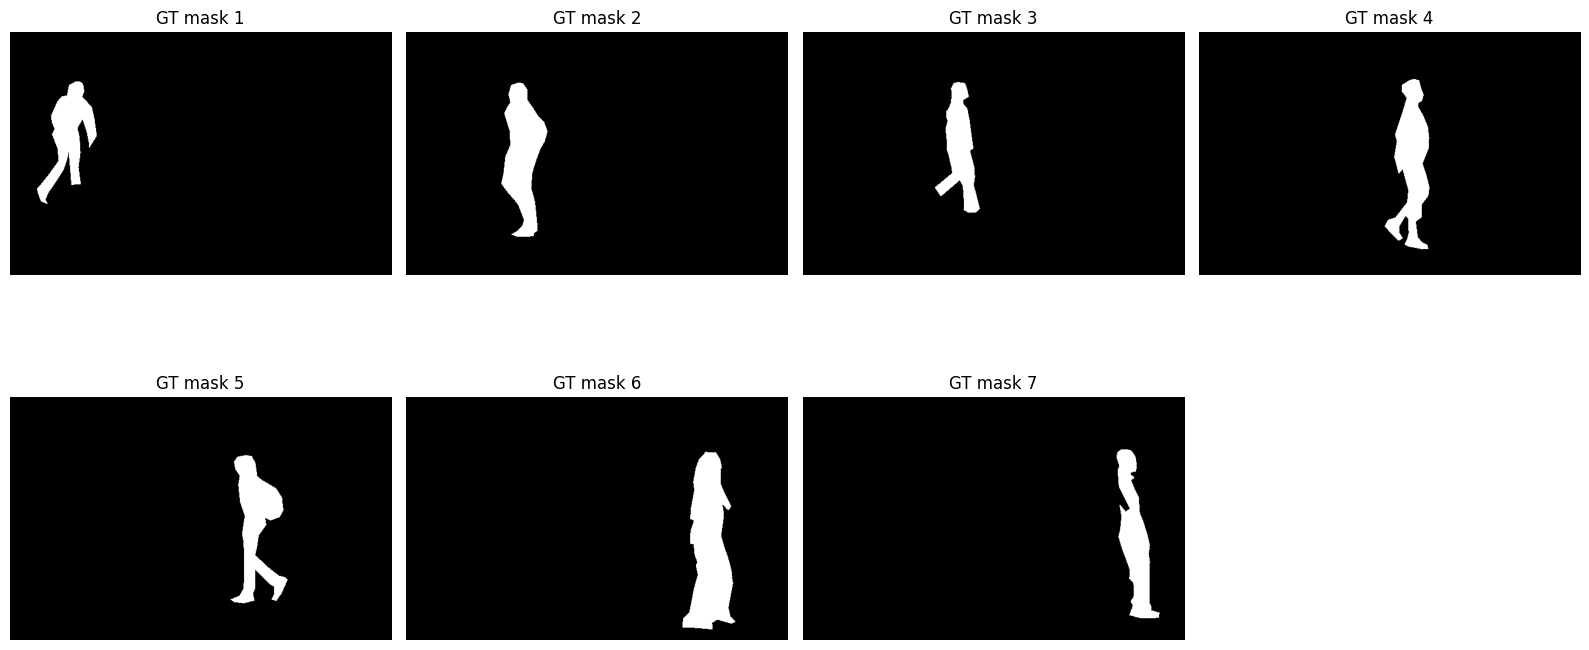

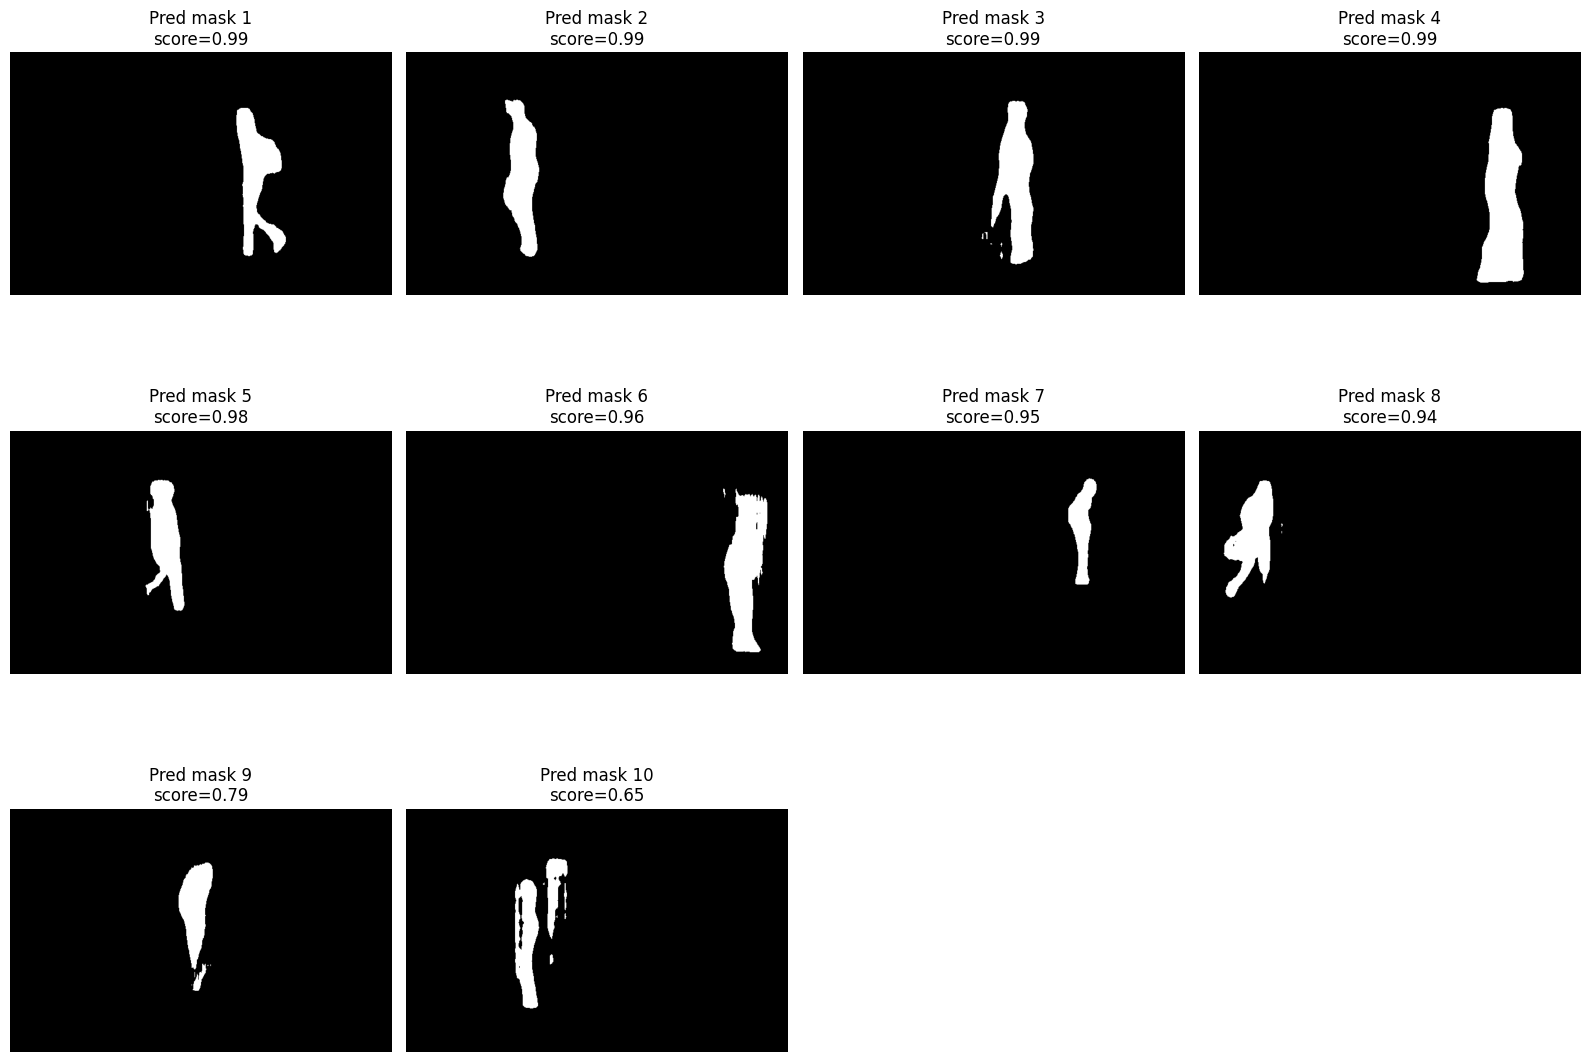

In [18]:

plain_val_dataset = PennFudanDataset(EXTRACTED_DIR, transforms=get_transform(train=False))

for example_idx in val_indices[:3]:
    image, target, output = predict_one(model, plain_val_dataset, example_idx, device, score_threshold=0.5)
    draw_predictions(image, target, output)

## Questions

1. Why does instance segmentation need both **boxes** and **masks**?
2. Why is Mask R-CNN a good transfer-learning model for a small dataset?
3. What happens if we increase:
   - the number of epochs?
   - the score threshold?
   - the batch size?
4. Why is our simplified validation IoU easier than full COCO evaluation?
5. How is instance segmentation different from object detection?

## Exercises

Try these extensions:

1. Train for **5 to 10 epochs** and compare the validation IoU.
2. Change the **score threshold** from `0.5` to `0.7`.
3. Add another simple augmentation, such as color jitter.
4. Save a trained model checkpoint:
   ```python
   torch.save(model.state_dict(), "maskrcnn_pennfudan.pth")
   ```
5. Replace the dataset with your own custom instance segmentation dataset in the same format.

## Summary

In this notebook, you learned how to:
- prepare a dataset for instance segmentation
- build the target dictionary required by TorchVision detection models
- fine-tune a pretrained **Mask R-CNN**
- train and validate the model
- visualize instance segmentation predictions